# HEC-RAS 2D results with pyramids-mesh

**HEC-RAS** (USACE) writes its 2D results into an HDF5 plan file (`*.pNN.hdf`). pyramids-mesh reads the 2D flow area's cell mesh and its summary results - `Maximum Water Surface` and `Minimum Water Surface`. This is the classic *Bald Eagle Creek dam-break* example.

The file holds two 2D flow areas; the driver reads the first (`BaldEagleCr`, 3,359 cells) and warns that selecting the other is not yet wired up.

## Setup

In [1]:
import os
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Image, display

def show():
    """Embed the current matplotlib figure as a PNG (Agg draws nothing on its own)."""
    from io import BytesIO
    buf = BytesIO()
    plt.gcf().savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close("all"); buf.seek(0)
    display(Image(data=buf.read()))

In [2]:
from pathlib import Path
import numpy as np
from pyramids.netcdf.ugrid import UgridDataset

# Paths are relative to THIS notebook (docs/examples/), never the repo root.
# read_file takes a pathlib.Path - pass Path objects, never str().
DATA = Path("../../examples/data")
DATA.resolve()

WindowsPath('C:/python-environments/worktrees/pyramids-mesh/example-notebooks/examples/data')

## What is on disk

In [3]:
for p in sorted((DATA / "hecras").iterdir()):
    print(p.name, f"({p.stat().st_size:,} bytes)")

BaldEagleDamBrk.p18.hdf (384,366 bytes)
SOURCE.txt (395 bytes)


## Quickstart read

Pass `driver="hecras"`. The `UserWarning` about the second flow area is expected - only `BaldEagleCr` is loaded.

In [4]:
ds = UgridDataset.read_file(DATA / "hecras" / "BaldEagleDamBrk.p18.hdf", driver="hecras")
ds

C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\drivers\hecras.py:200: UserWarning: '..\\..\\examples\\data\\hecras\\BaldEagleDamBrk.p18.hdf' holds 2 2D flow areas ['BaldEagleCr', 'Upper 2D Area']; only the first ('BaldEagleCr') is read -- selecting another is not wired yet
  area = self._select_area(areas)


UgridDataset(mesh='mesh2d', n_node=3937, n_face=3359, n_edge=0, variables=['Maximum Water Surface', 'Minimum Water Surface'])

These are summary fields (no time axis): the maximum and minimum water-surface elevation reached in each cell over the simulation.

## Explore the dataset

A `UgridDataset` wraps a UGRID-style unstructured mesh plus any data variables that ride on it. The scalar properties below describe the grid at a glance: how many nodes and faces it has, its coordinate reference system, and its spatial extent.

The cells are a mixed-polygon mesh (3 to 7 vertices per face) in projected feet.

In [5]:
print("n_node:", ds.n_node)
print("n_face:", ds.n_face)
print("crs:   ", ds.crs)
print("epsg:  ", ds.epsg)
print("bounds:", ds.bounds)  # (xmin, ymin, xmax, ymax)

n_node: 3937
n_face: 3359
crs:    None
epsg:   None
bounds: (2000930.7770462395, 320392.943840647, 2084780.0343864076, 370965.91688711394)


`crs`/`epsg` are often `None`: many hydraulic-model result files store coordinates without an embedded CRS, so pyramids reports the geometry faithfully and leaves georeferencing to you. The `bounds` tuple is the mesh envelope in the file's own coordinate units.

### Data variables

`data_variable_names` lists every field attached to the mesh. These are the real model results - water levels, depths, velocities - that make a results file worth reading.

In [6]:
ds.data_variable_names

['Maximum Water Surface', 'Minimum Water Surface']

`summary()` returns a tidy `pandas.DataFrame` of per-variable statistics (count, min, max, mean, std) - a quick sanity check on magnitudes and fill values.

In [7]:
ds.summary()

,count,min,max,mean,std
variable,,,,,
Maximum Water Surface,3359,537.211121,764.279785,587.039248,31.895550
Minimum Water Surface,3359,527.152527,764.279785,578.899219,36.926533


## The Mesh2d geometry

`ds.mesh` is a `Mesh2d`: the topology the data variables are defined on. Nodes carry the `(x, y)` coordinates; `face_node_connectivity` says which nodes form each face (a row per face, padded to the maximum vertex count).

In [8]:
mesh = ds.mesh
nx, ny = np.asarray(mesh.node_x), np.asarray(mesh.node_y)
fnc = np.asarray(mesh.face_node_connectivity.data)
print("node_x:", nx.shape, " node_y:", ny.shape)
print("face_node_connectivity:", fnc.shape, " (n_face, max_vertices)")
fnc[:3]

node_x: (3937,)  node_y: (3937,)
face_node_connectivity: (3359, 7)  (n_face, max_vertices)


array([[   0,    1,    2,    3,   -1,   -1,   -1],
       [   0,    4, 3895,    1,   -1,   -1,   -1],
       [   5,    6,    7,    8,   -1,   -1,   -1]])

`face_areas` gives the area of every face; `face_centroids` is a `(2, n_face)` array of face centre coordinates. Both are derived straight from the topology.

In [9]:
areas = np.asarray(mesh.face_areas)
cen = np.asarray(mesh.face_centroids)  # shape (2, n_face)
print("face_areas:", areas.shape, " mean area:", round(float(areas.mean()), 4))
print("face_centroids:", cen.shape)

face_areas: (3359,)  mean area: 257902.3253
face_centroids: (2, 3359)


## Wireframe - the bare mesh

`plot_outline()` draws the mesh edges with no data colouring. It is the fastest way to see the grid's shape, resolution, and how faces are distributed before looking at any results.

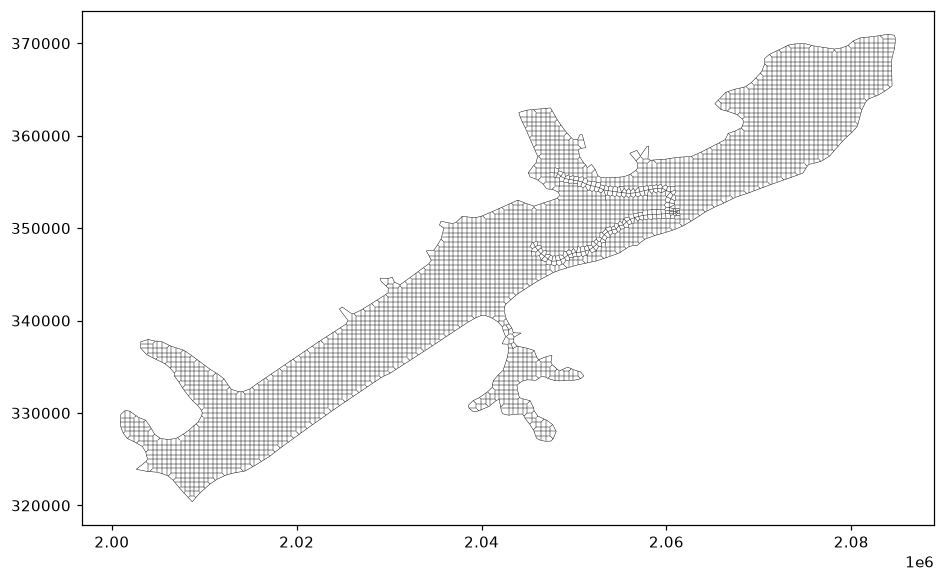

In [10]:
ds.plot_outline()
show()

## Mapping the real results

Both variables are per-cell summaries, so they map directly with no timestep to pick. The maximum water surface traces the dam-break flood extent; the minimum shows the lowest stage each cell saw.

## Mapping the real results

These files carry genuine model output, so the point of the package is to *see* it. `ds.plot(variable, cmap=..., colorbar=..., title=...)` colours each face by its value and routes through cleopatra (reached via pyramids) for the actual rendering.

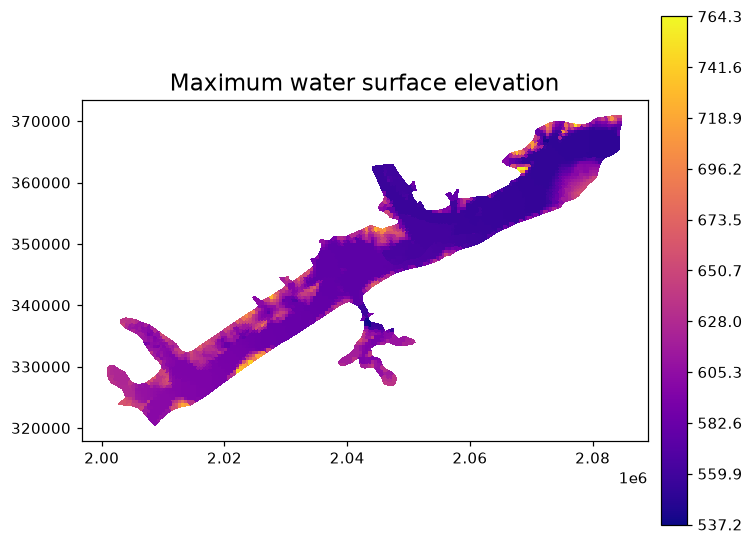

In [11]:
ds.plot("Maximum Water Surface", cmap="plasma", colorbar=True, title="Maximum water surface elevation")
show()

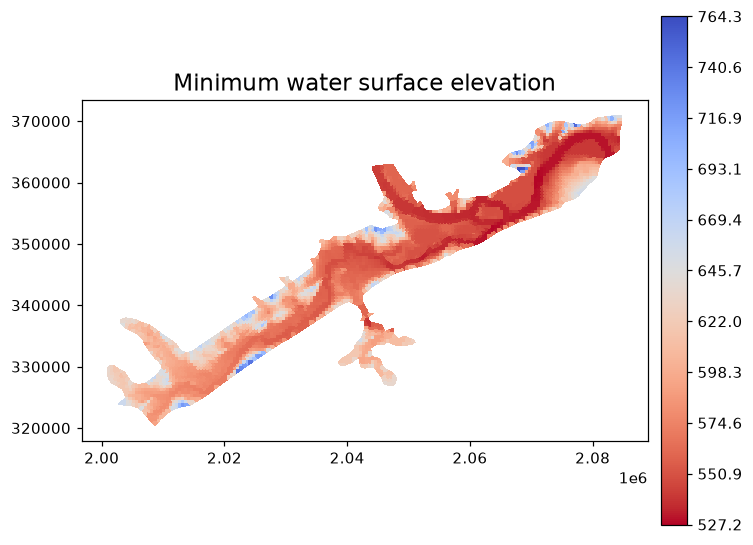

In [12]:
ds.plot("Minimum Water Surface", cmap="viridis", colorbar=True, title="Minimum water surface elevation")
show()

## From mesh to GIS

A `UgridDataset` is not a dead end - it converts into the vector and raster types the rest of a GIS workflow expects. Everything below is reached through pyramids; this package only supplies the file-format driver that built the mesh.

### Faces as vector polygons

`to_geodataframe(variable_name=...)` turns every face into a polygon row carrying that variable's value - a standard GeoPandas `GeoDataFrame` you can join, filter, or export.

In [13]:
gdf = ds.to_geodataframe(variable_name="Maximum Water Surface")
print("rows:", len(gdf), " columns:", list(gdf.columns), " crs:", gdf.crs)
gdf.head()

rows: 3359  columns: ['Maximum Water Surface', 'geometry']  crs: None


,Maximum Water Surface,geometry
0,658.762207,"POLYGON ((2083930.7 370507.583, 2083930.7 3709..."
1,648.673340,"POLYGON ((2083930.7 370507.583, 2084780.034 37..."
2,609.591919,"POLYGON ((2080930.7 370007.583, 2080930.7 3705..."
3,622.499756,"POLYGON ((2080930.7 370577.568, 2080930.7 3700..."
4,639.792175,"POLYGON ((2081430.7 370634.206, 2081430.7 3700..."


Plotting that `GeoDataFrame` straight through GeoPandas (matplotlib under the hood) gives a choropleth of the same values, now as independent vector features.

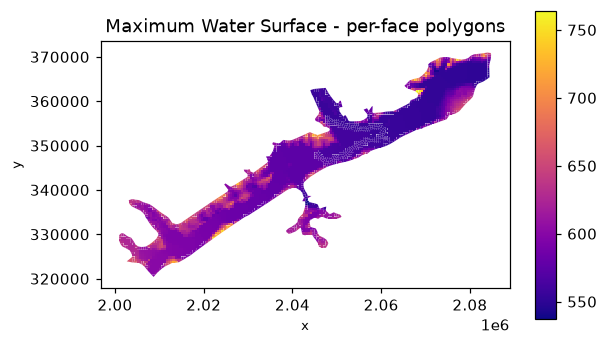

In [14]:
gdf.plot(column="Maximum Water Surface", cmap="plasma", legend=True, figsize=(6, 5))
plt.title("Maximum Water Surface - per-face polygons")
show()

### Dissolving into zones

`polygonize(variable)` merges neighbouring faces that share a value into larger polygons - handy for turning a noisy per-cell field into clean zones. It needs a single value per face, which is exactly what our working dataset holds.

dissolved polygons: 3161  columns: ['value', 'geometry']


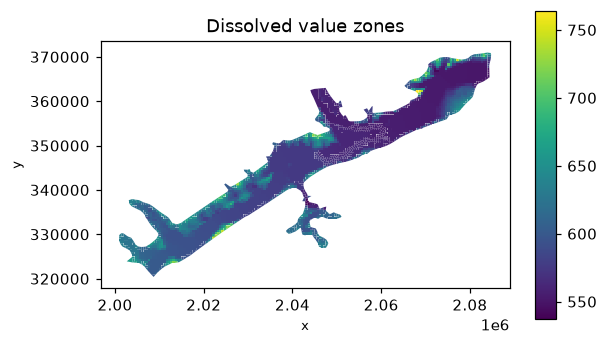

In [15]:
zones = ds.polygonize("Maximum Water Surface")
print("dissolved polygons:", len(zones), " columns:", list(zones.columns))
zones.plot(column="value", cmap="viridis", legend=True, figsize=(6, 5))
plt.title("Dissolved value zones")
show()

### Sampling at points

`sample(variable, x, y)` reads the value of the face that contains each query point. Here we probe the first few face centroids, so each query lands squarely inside a face.

In [16]:
cen = np.asarray(ds.mesh.face_centroids)
xs, ys = cen[0][:5], cen[1][:5]
vals = ds.sample("Maximum Water Surface", xs, ys)
for x, y, v in zip(xs, ys, np.asarray(vals)):
    print(f"({x:10.2f}, {y:10.2f}) -> {float(v):.4f}")

(2083680.70,  370757.58) -> 658.7622
(2084180.70,  370757.58) -> 648.6733
(2080680.70,  370257.58) -> 609.5919
(2081180.70,  370257.58) -> 622.4998
(2081680.70,  370257.58) -> 639.7922


### The mesh outline as one polygon

`bounding_polygon()` returns a single shapely polygon tracing the mesh's outer boundary - the model's wetted footprint, useful as a clip mask or extent reference.

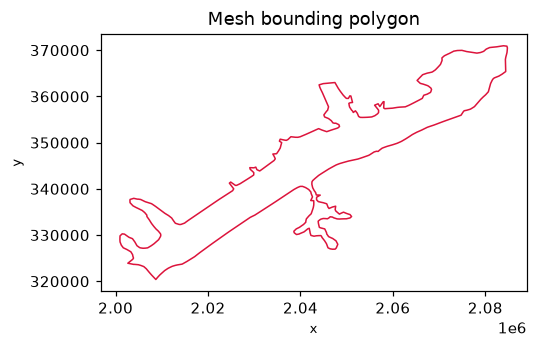

In [17]:
poly = ds.bounding_polygon()
import geopandas as gpd
gpd.GeoSeries([poly]).plot(facecolor="none", edgecolor="crimson", figsize=(5, 5))
plt.title("Mesh bounding polygon")
show()

### Cropping to a sub-region

`subset_by_bounds(xmin, ymin, xmax, ymax)` returns a new, smaller `UgridDataset` holding only the faces inside the box - the same object type, so every operation above still applies. We derive a box from the mesh envelope so it works on any extent.

faces in full mesh: 3359  -> in subset: 1339


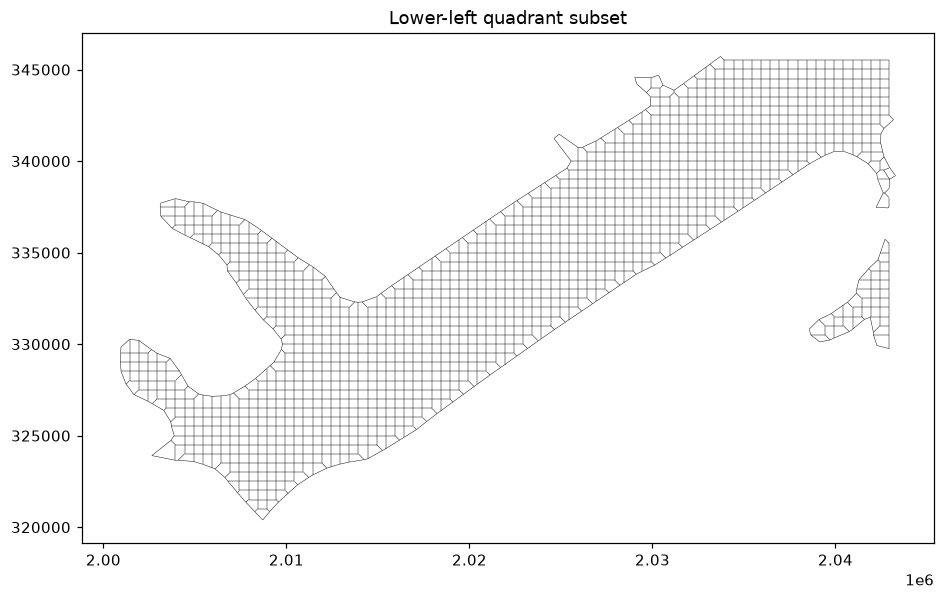

In [18]:
xmin, ymin, xmax, ymax = ds.bounds
mx, my = (xmin + xmax) / 2, (ymin + ymax) / 2
sub = ds.subset_by_bounds(xmin, ymin, mx, my)
print("faces in full mesh:", ds.n_face, " -> in subset:", sub.n_face)
sub.plot_outline()
plt.title("Lower-left quadrant subset")
show()

### Connectivity as a sparse graph

`sparse_adjacency()` exposes face-to-face adjacency as a SciPy sparse matrix, and `connected_components()` labels each face by which connected piece of the mesh it belongs to - the entry points for graph algorithms over the grid.

In [19]:
adj = ds.sparse_adjacency()
print("adjacency:", adj.shape, " non-zeros:", adj.nnz)
labels = ds.connected_components()
print("connected components:", len(np.unique(np.asarray(labels))))

adjacency: (3359, 3359)  non-zeros: 13414
connected components: 1


### Circumcenters - not applicable here

`circumcenters()` is only defined for purely triangular meshes. This grid contains quad (or mixed-polygon) faces, so the call would raise `ValueError`. We note it and skip rather than force it.

### Self-contained rasterisation

`to_dataset(variable, cell_size=...)` samples the mesh onto a regular raster grid and returns a pyramids `Dataset`. Unlike `rasterize_like` / `regrid` - which need an existing reference grid and are therefore skipped here - this is self-contained: you only choose a cell size.

rasterised to: Dataset


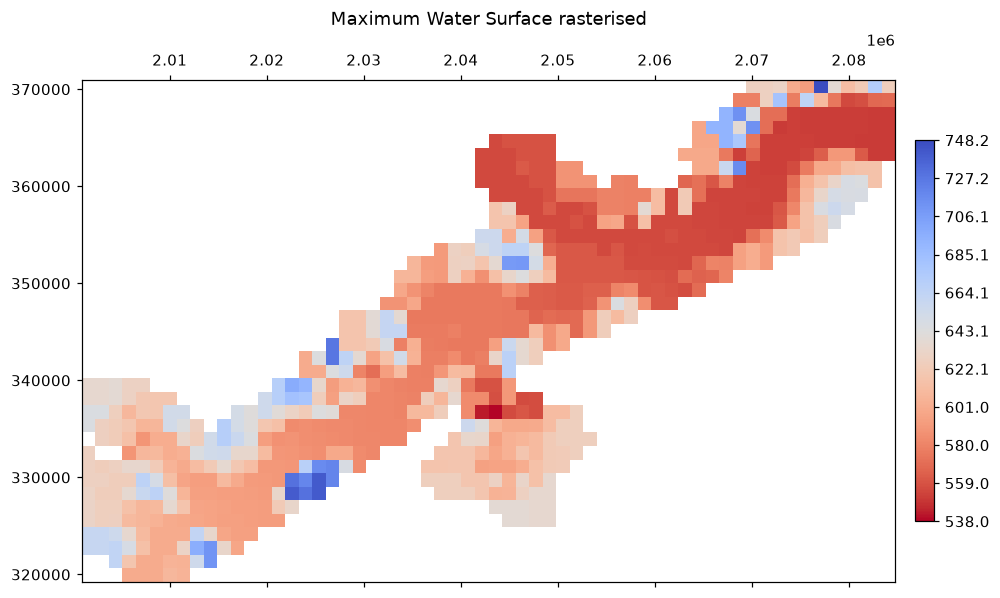

In [20]:
step_xy = (ds.bounds[2] - ds.bounds[0]) / 60
rast = ds.to_dataset("Maximum Water Surface", cell_size=step_xy)
print("rasterised to:", type(rast).__name__)
rast.plot()
plt.title("Maximum Water Surface rasterised")
show()

### Reprojection - skipped

`to_crs(...)` needs a *source* CRS to project from. This HEC-RAS plan file reports no CRS to the driver, so `ds.crs` is `None` (the coordinates are projected feet). With no source CRS, reprojection is undefined, so we skip it; assign a CRS first if your coordinates are georeferenced.

### Back to xarray

`to_xarray()` hands the whole dataset back as an `xarray.Dataset`, so you can drop into the full xarray ecosystem (time selection, resampling, NetCDF export) whenever you need it.

In [21]:
xds = ds.to_xarray()
type(xds).__name__, list(xds.data_vars)[:6]

('Dataset',
 ['mesh2d',
  'mesh2d_node_x',
  'mesh2d_node_y',
  'mesh2d_face_nodes',
  'mesh2d_face_x',
  'mesh2d_face_y'])

## Takeaway

HEC-RAS stores a mixed-polygon 2D mesh with summary water-surface results in an HDF5 plan file. pyramids-mesh reads the first flow area (reporting the unread one), exposes `Maximum`/`Minimum Water Surface` as plain per-cell fields that map directly, and lets the whole pyramids GIS toolkit operate on the result. The driver parses the plan file; the mesh analysis belongs to pyramids.